In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
sinr_threshold = pd.read_csv(
    "/home/alex/inatVisionApi/v2_17_sinr_coords_elev_dropout/thresholds.csv"
).set_index("taxon_id")
grid_threshold = pd.read_csv(
    "/home/alex/inatVisionApi/v2_17_fast/thresholds.csv"
).set_index("taxon_id")

In [3]:
sinr_eval = pd.read_csv(
    "/home/alex/inatVisionApi/v2_17_sinr_coords_elev_dropout/tf_env_eval_test.csv"
).set_index("taxon_id")
grid_eval = pd.read_csv(
    "/home/alex/inatVisionApi/v2_17_fast/tf_env_eval_test.csv"
).set_index("taxon_id")

In [4]:
merged = pd.merge(
    sinr_eval,
    grid_eval,
    left_index=True,
    right_index=True,
    suffixes=["_sinr", "_grid"],
)

In [6]:
merged["prauc_diff"] = merged["prauc_sinr"]-merged["prauc_grid"]

In [7]:
merged.columns

Index(['Unnamed: 0_sinr', 'prauc_sinr', 'p_sinr', 'r_sinr', 'f1_sinr',
       'taxon_range_area_sinr', 'Unnamed: 0_grid', 'prauc_grid', 'p_grid',
       'r_grid', 'f1_grid', 'taxon_range_area_grid', 'prauc_diff'],
      dtype='object')

<Axes: xlabel='taxon_range_area_grid', ylabel='prauc_diff'>

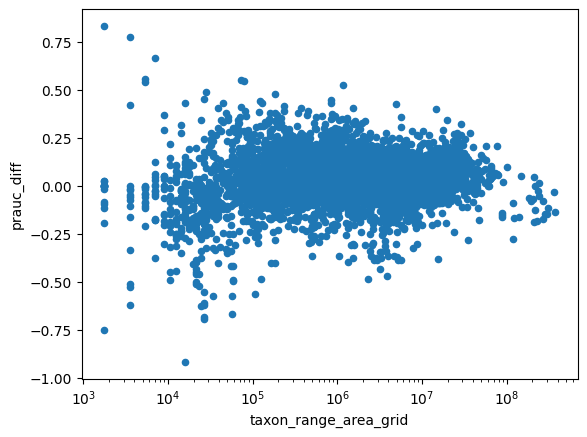

In [8]:
merged.plot.scatter(
    x="taxon_range_area_grid",
    y="prauc_diff",
    logx=True,
)

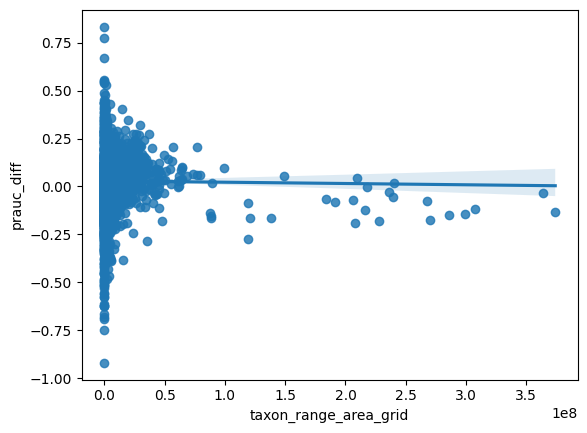

In [9]:
# Create a scatter plot
sns.scatterplot(
    data=merged, 
    x='taxon_range_area_grid', 
    y='prauc_diff',
    alpha=0.1
)

# Add regression line
sns.regplot(
    data=merged, 
    x='taxon_range_area_grid', 
    y='prauc_diff'
)

# Show the plot
# plt.xscale("log")

plt.show()

In [10]:
merged.sort_values("prauc_diff")

,Unnamed: 0_sinr,prauc_sinr,p_sinr,r_sinr,f1_sinr,taxon_range_area_sinr,Unnamed: 0_grid,prauc_grid,p_grid,r_grid,f1_grid,taxon_range_area_grid,prauc_diff
taxon_id,,,,,,,,,,,,,
200000,1437,0.055306,0.102564,0.444444,0.166667,15932.911968,1437,0.975154,0.888889,0.888889,0.888889,15932.911968,-0.919848
733752,2943,0.250000,0.500000,1.000000,0.666667,1770.323552,2943,1.000000,1.000000,1.000000,1.000000,1770.323552,-0.750000
16057,1668,0.264129,0.080000,0.666667,0.142857,26554.853280,1668,0.957333,0.833333,1.000000,0.909091,26554.853280,-0.693205
18159,1839,0.286246,0.106383,0.666667,0.183486,26554.853280,1839,0.969664,0.833333,1.000000,0.909091,26554.853280,-0.683418
1367052,3784,0.311587,0.072727,0.500000,0.126984,56650.353664,3784,0.978337,1.000000,0.281250,0.439024,56650.353664,-0.666750
...,...,...,...,...,...,...,...,...,...,...,...,...,...
564489,3464,0.816364,0.785714,0.804878,0.795181,72583.265632,3464,0.266440,0.119691,0.756098,0.206667,72583.265632,0.549924
95898,3871,0.816667,0.500000,1.000000,0.666667,5310.970656,3871,0.260684,0.230769,1.000000,0.375000,5310.970656,0.555983
33112,3114,0.870833,0.235294,1.000000,0.380952,7081.294208,3114,0.201027,0.148148,1.000000,0.258065,7081.294208,0.669806


<Axes: xlabel='taxon_range_area_grid', ylabel='prauc_diff'>

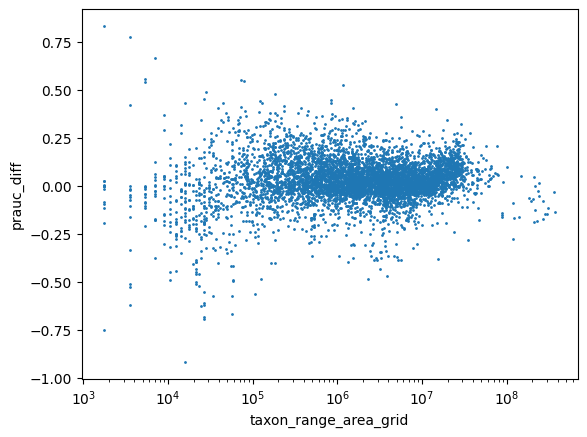

In [11]:
merged.sort_values("taxon_range_area_grid").tail(50_000).plot.scatter(
    x="taxon_range_area_grid",
    y="prauc_diff",
    logx=True,
    s=1
)

In [12]:
merged_lrs = merged[merged.taxon_range_area_grid>merged.taxon_range_area_grid.mean()]

In [13]:
merged_lrs.sort_values("prauc_diff")

,Unnamed: 0_sinr,prauc_sinr,p_sinr,r_sinr,f1_sinr,taxon_range_area_sinr,Unnamed: 0_grid,prauc_grid,p_grid,r_grid,f1_grid,taxon_range_area_grid,prauc_diff
taxon_id,,,,,,,,,,,,,
4041,2184,0.555686,0.999318,0.166724,0.285770,1.555583e+07,2184,0.939315,1.000000,0.306020,0.468630,1.555583e+07,-0.383628
83170,5075,0.374895,0.450482,0.261287,0.330740,7.920428e+06,5075,0.699589,0.500645,0.780510,0.610010,7.920428e+06,-0.324694
41714,4420,0.488385,0.603395,0.159592,0.252421,8.674585e+06,4420,0.790218,0.964760,0.430204,0.595060,8.674585e+06,-0.301832
62739,5525,0.608330,0.854066,0.372407,0.518658,3.524891e+07,5525,0.891156,0.954862,0.509969,0.664855,3.524891e+07,-0.282825
4054,2185,0.551872,0.761320,0.082015,0.148078,1.190436e+08,2185,0.828218,0.876234,0.138555,0.239275,1.190436e+08,-0.276346
...,...,...,...,...,...,...,...,...,...,...,...,...,...
101334,4871,0.569280,0.799561,0.249358,0.380157,1.033692e+07,4871,0.281261,0.316131,0.350402,0.332386,1.033692e+07,0.288019
503686,6014,0.658235,0.974457,0.077446,0.143488,1.744123e+07,6014,0.365311,0.336374,0.265733,0.296910,1.744123e+07,0.292924
110115,5946,0.511699,0.881572,0.100557,0.180523,2.922450e+07,5946,0.188372,0.179875,0.185062,0.182432,2.922450e+07,0.323328
